# eepyAI

### Import libraries, load data, remove IDs

In [22]:
import pandas as pd
import numpy as np
from src.DataAnalyzer import DataAnalyzer
from src.DataSplitter import DataSplitter
from src.ModelTrainer import ModelTrainer
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import matplotlib.pyplot as plt

df = pd.read_csv("data/bedtime_screentime_sleep_debt.csv")
if 'user_id' in df.columns:
    df = df.drop(columns=['user_id'])
df.head(100)

,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,32,Male,Freelance / Creative,Intermediate,93,TikTok / Reels,46,1,0,49,67.6,5.43,27.5,17.9,3,4.3,Moderate Debt
96,33,Male,Student,Morning Lark,62,News / Reading,58,0,0,27,34.1,7.04,20.4,19.5,1,1.0,Mild Deficit
97,30,Female,Corporate 9-to-5,Night Owl,117,TikTok / Reels,36,0,109,51,75.5,3.37,22.7,14.6,7,10.0,Severe Sleep Debt
98,18,Male,Corporate 9-to-5,Intermediate,22,Instagram / Reddit,53,0,129,11,39.9,6.91,22.0,15.5,2,3.1,Mild Deficit


### Print basic info and statistics

In [23]:
analyzer = DataAnalyzer(df)
analyzer.basic_info()
analyzer.statistics()
analyzer.unique()

<class 'pandas.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       8500 non-null   int64  
 1   gender                    8500 non-null   str    
 2   occupation_type           8500 non-null   str    
 3   chronotype                8500 non-null   str    
 4   bedtime_phone_minutes     8500 non-null   int64  
 5   primary_bedtime_app       8500 non-null   str    
 6   screen_brightness_pct     8500 non-null   int64  
 7   blue_light_filter_active  8500 non-null   int64  
 8   caffeine_post_5pm_mg      8500 non-null   int64  
 9   physical_activity_min     8500 non-null   int64  
 10  sleep_latency_min         8500 non-null   float64
 11  total_sleep_hours         8500 non-null   float64
 12  deep_sleep_pct            8500 non-null   float64
 13  rem_sleep_pct             8500 non-null   float64
 14  morning_alarm_snooz

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score
count,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000
mean,34.355647,59.250000,55.153882,0.467765,33.222471,35.701412,40.671471,6.266209,21.735741,19.105859,2.766000,3.794671
std,11.584259,36.931991,19.850550,0.498989,51.935645,20.819390,17.444914,1.446258,3.069377,2.546459,1.695407,2.685153
min,18.000000,1.000000,10.000000,0.000000,0.000000,0.000000,6.000000,3.200000,8.100000,9.600000,0.000000,1.000000
25%,25.000000,31.000000,42.000000,0.000000,0.000000,21.000000,28.200000,5.240000,19.700000,17.400000,2.000000,1.100000
50%,32.000000,51.000000,55.000000,0.000000,0.000000,35.000000,37.600000,6.330000,21.900000,19.100000,3.000000,3.200000
75%,42.000000,79.000000,69.000000,1.000000,55.000000,50.000000,49.700000,7.350000,23.900000,20.800000,4.000000,5.600000
max,65.000000,180.000000,100.000000,1.000000,250.000000,112.000000,123.300000,9.800000,28.000000,27.000000,7.000000,10.000000


---------------------------------------------------------------
There are 5 non-numerical columns:
	gender - 3 values:
		Female
		Non-Binary
		Male
	occupation_type - 5 values:
		Healthcare / Shift Worker
		Student
		Remote Tech
		Freelance / Creative
		Corporate 9-to-5
	chronotype - 3 values:
		Intermediate
		Night Owl
		Morning Lark
	primary_bedtime_app - 6 values:
		Instagram / Reddit
		YouTube
		TikTok / Reels
		News / Reading
		Streaming (Netflix/Hulu)
		Messaging / Chat
	sleep_debt_category - 4 values:
		Severe Sleep Debt
		Mild Deficit
		Moderate Debt
		Optimal Recovery
---------------------------------------------------------------


### Perform one-hot encoding and visualize data

In [ ]:
columns_to_encode = df.select_dtypes(include=['object']).columns
df = pd.get_dummies(df, columns=columns_to_encode, drop_first=False, dtype=int)

analyzer = DataAnalyzer(df)
analyzer.histogram("next_day_fatigue_score")
analyzer.histogram_all_columns()
analyzer.correlation_heatmap()

### Split the dataset

In [25]:
splitter = DataSplitter(df, "next_day_fatigue_score", 0.2)
X_train, X_test, y_train, y_test = splitter.split()

### Train model with training data (Michal S)

In [26]:
modelTrainer=ModelTrainer()
modelTrainer.train(X_train, y_train)

### Test model with test data and check MAE. Compare models (Michal S)

In [27]:
# 1. predykcje wszystkich modeli na zbiorze testowym
predictions = modelTrainer.predict(X_test)

# 2. metryki dla każdego modelu
results = []
for name, y_pred in predictions.items():
    results.append({
        "model": name,
        "MAE":  mean_absolute_error(y_test, y_pred),
        "RMSE": root_mean_squared_error(y_test, y_pred),
        "R2":   r2_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).set_index("model").sort_values("MAE").round(3)
results_df

,MAE,RMSE,R2
model,,,
LinearRegression,0.470,0.633,0.945
DummyMean,2.256,2.697,-0.000


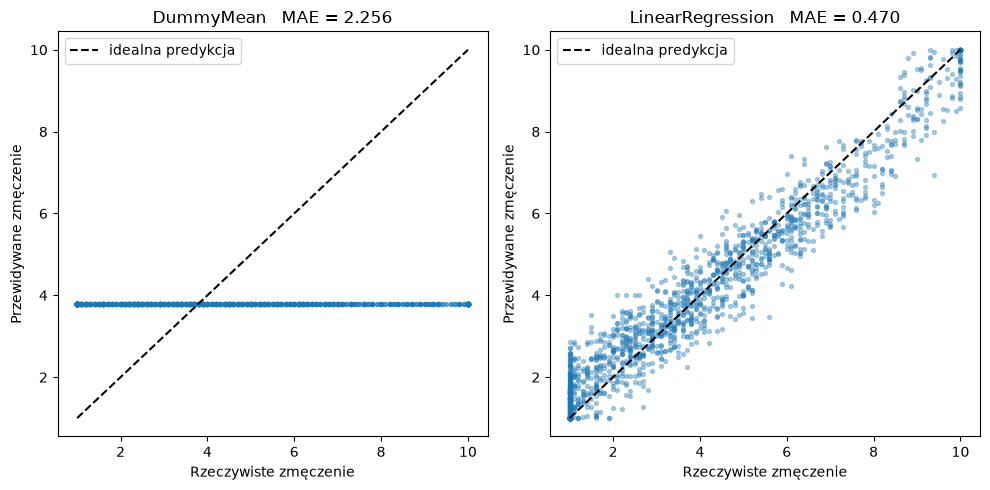

In [39]:
fig, axes = plt.subplots(1, len(predictions), figsize=(5 * len(predictions), 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, s=8, alpha=0.35)
    ax.plot([1, 10], [1, 10], "k--", label="idealna predykcja")
    ax.set_title(f"{name}   MAE = {results_df.loc[name, 'MAE']:.3f}")
    ax.set_xlabel("Rzeczywiste zmęczenie")
    ax.set_ylabel("Przewidywane zmęczenie")
    ax.legend()

plt.tight_layout()
plt.show()